In [97]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

In [105]:
%matplotlib qt
plt.ion()
points=[]
while True:
    plt.figure()
    plt.plot([0,1],[0,1], 'w.')

    c = plt.ginput(100, mouse_stop=2,show_clicks=True)

    if len(c) == 0:
        break
    points.append(np.array(c))
    plt.draw()
    plt.close()

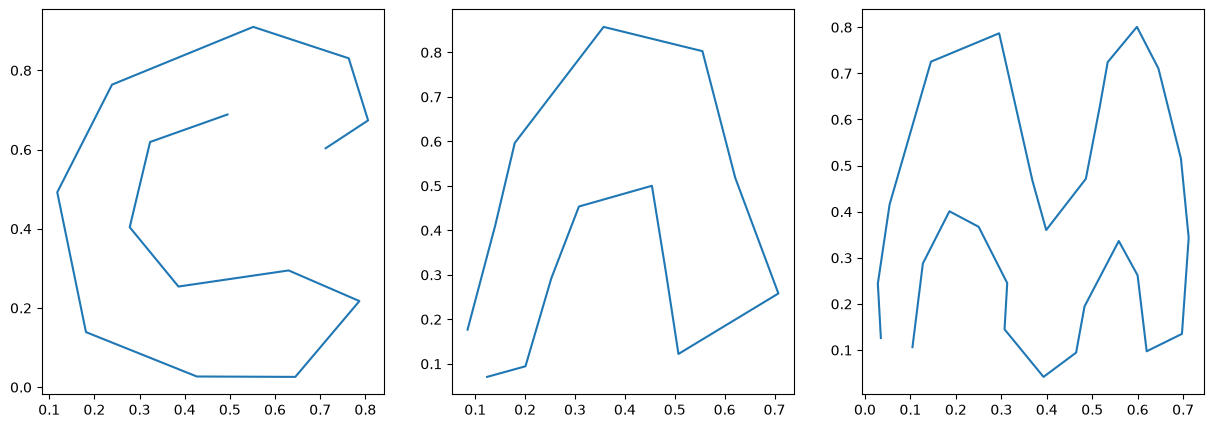

In [106]:
%matplotlib inline
fig,ax = plt.subplots(1,len(points),figsize=(15,5))
for i in range(len(points)):
    ax[i].plot(points[i][:,0],points[i][:,1])

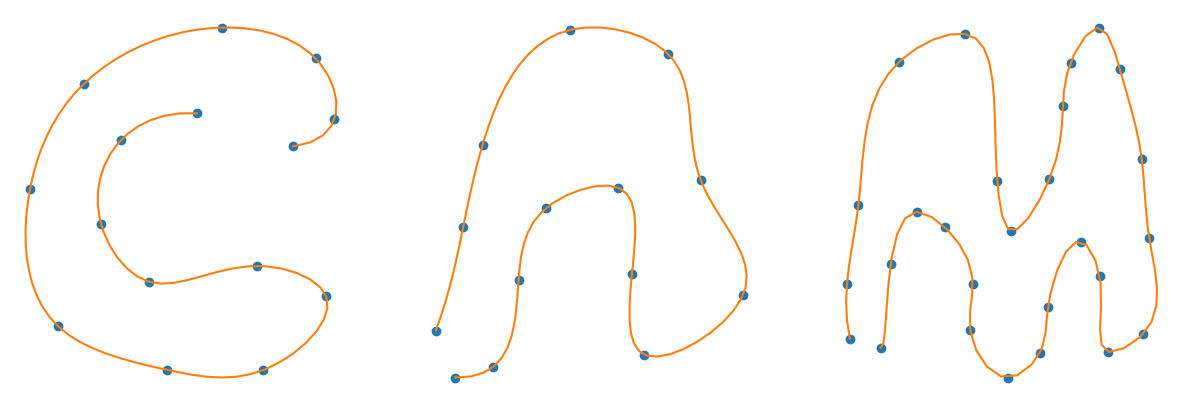

In [107]:
fig,ax = plt.subplots(1,len(points),figsize=(5*len(points),5))
for i,p in enumerate(points):
    distances = np.linalg.norm(np.diff(p,axis=0),axis=1)
    t = np.concatenate([[0],np.cumsum(distances)])

    X_is = make_interp_spline(t,p[:,0])
    Y_is = make_interp_spline(t,p[:,1])

    times = np.linspace(t[0],t[-1],100)

    ax[i].set_axis_off()
    ax[i].plot(p[:,0],p[:,1],'o')
    ax[i].plot(X_is(times),Y_is(times),'-')